# **Step-1: Install libraries**

In [ ]:
!pip install opencv-python pillow matplotlib


# **Step-2: Import Libraries**

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from google.colab import files

# **Step-3: Upload Image**

In [ ]:
uploaded = files.upload()


# **Step-4: Load image**

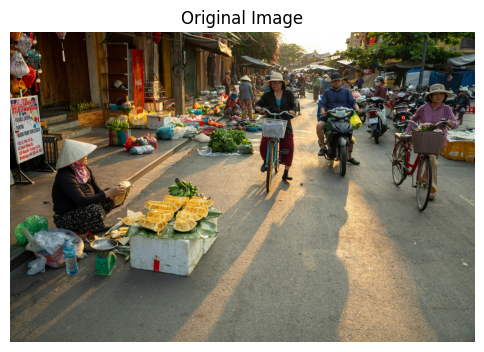

In [ ]:
# Get uploaded filename automatically
image_name = list(uploaded.keys())[0]

image = cv2.imread(image_name)

if image is None:
    print("Error: Image not found.")
else:
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    plt.figure(figsize=(6,6))
    plt.imshow(image)
    plt.title("Original Image")
    plt.axis("off")

# **Step-5: Preprocessing**

(np.float64(-0.5), np.float64(2999.5), np.float64(1999.5), np.float64(-0.5))

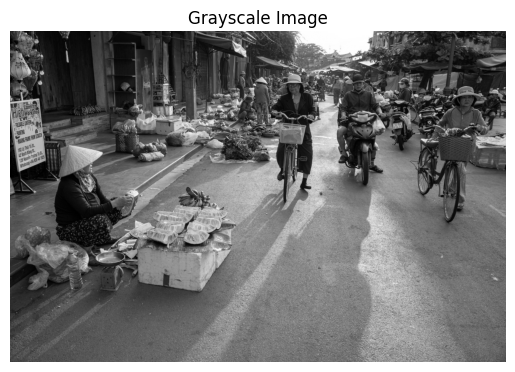

In [ ]:
gray = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)

plt.imshow(gray, cmap='gray')
plt.title("Grayscale Image")
plt.axis("off")

# **Step-6: Spatial Analysis (Edge Detection)**

(np.float64(-0.5), np.float64(2999.5), np.float64(1999.5), np.float64(-0.5))

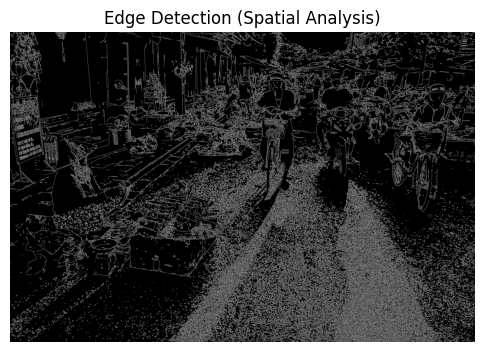

In [ ]:
edges = cv2.Canny(gray,100,200)

plt.figure(figsize=(6,6))
plt.imshow(edges, cmap='gray')
plt.title("Edge Detection (Spatial Analysis)")
plt.axis("off")

# **Step-7: Frequency Domain Analysis (FFT)**

(np.float64(-0.5), np.float64(2999.5), np.float64(1999.5), np.float64(-0.5))

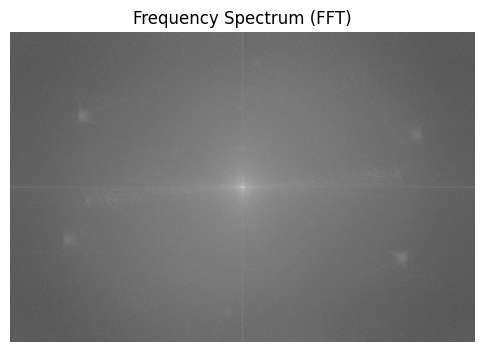

In [ ]:
f = np.fft.fft2(gray)

fshift = np.fft.fftshift(f)

magnitude_spectrum = 20 * np.log(np.abs(fshift) + 1)

plt.figure(figsize=(6,6))
plt.imshow(magnitude_spectrum, cmap='gray')
plt.title("Frequency Spectrum (FFT)")
plt.axis("off")

# **Step-8: Frequency Analysis (DCT)**

(np.float64(-0.5), np.float64(2999.5), np.float64(1999.5), np.float64(-0.5))

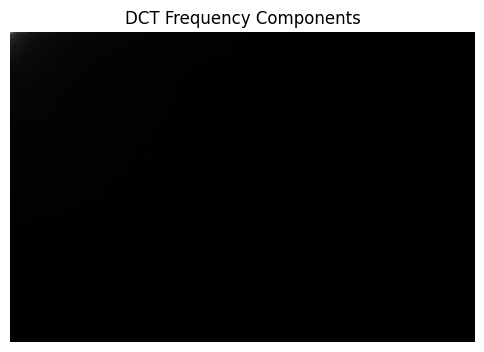

In [ ]:
gray_float = np.float32(gray)/255.0

dct = cv2.dct(gray_float)

plt.figure(figsize=(6,6))
plt.imshow(np.log(abs(dct)+1), cmap='gray')
plt.title("DCT Frequency Components")
plt.axis("off")

# **Step-8: Error Level Analysis (ELA)**

(np.float64(-0.5), np.float64(2999.5), np.float64(1999.5), np.float64(-0.5))

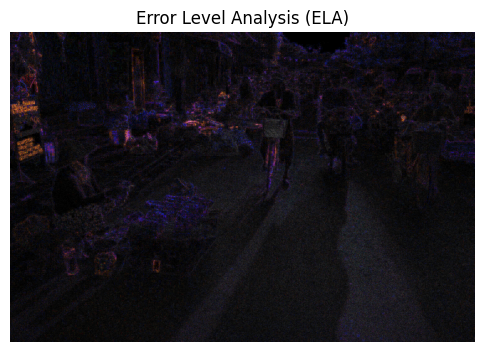

In [ ]:
temp_filename = 'temp_compressed.jpg'

cv2.imwrite(temp_filename, cv2.cvtColor(image, cv2.COLOR_RGB2BGR),
            [int(cv2.IMWRITE_JPEG_QUALITY), 90])

recompressed = cv2.imread(temp_filename)
recompressed = cv2.cvtColor(recompressed, cv2.COLOR_BGR2RGB)

ela = cv2.absdiff(image, recompressed)
ela = cv2.convertScaleAbs(ela, alpha=25)

plt.figure(figsize=(6,6))
plt.imshow(ela)
plt.title("Error Level Analysis (ELA)")
plt.axis("off")

# **Step-9: Forgery Heatmap Generation**

(np.float64(-0.5), np.float64(2999.5), np.float64(1999.5), np.float64(-0.5))

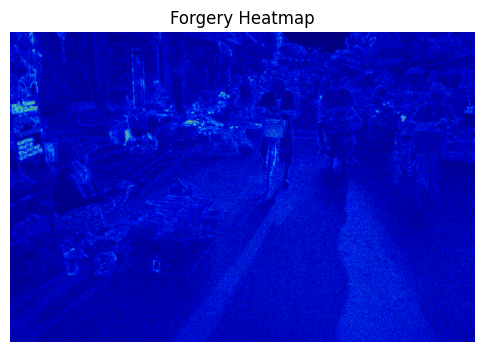

In [ ]:
ela_gray = cv2.cvtColor(ela, cv2.COLOR_RGB2GRAY)

heatmap = cv2.applyColorMap(ela_gray, cv2.COLORMAP_JET)

heatmap = cv2.cvtColor(heatmap, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(6,6))
plt.imshow(heatmap)
plt.title("Forgery Heatmap")
plt.axis("off")

# **Step-10: Final Visualization Dashboard**

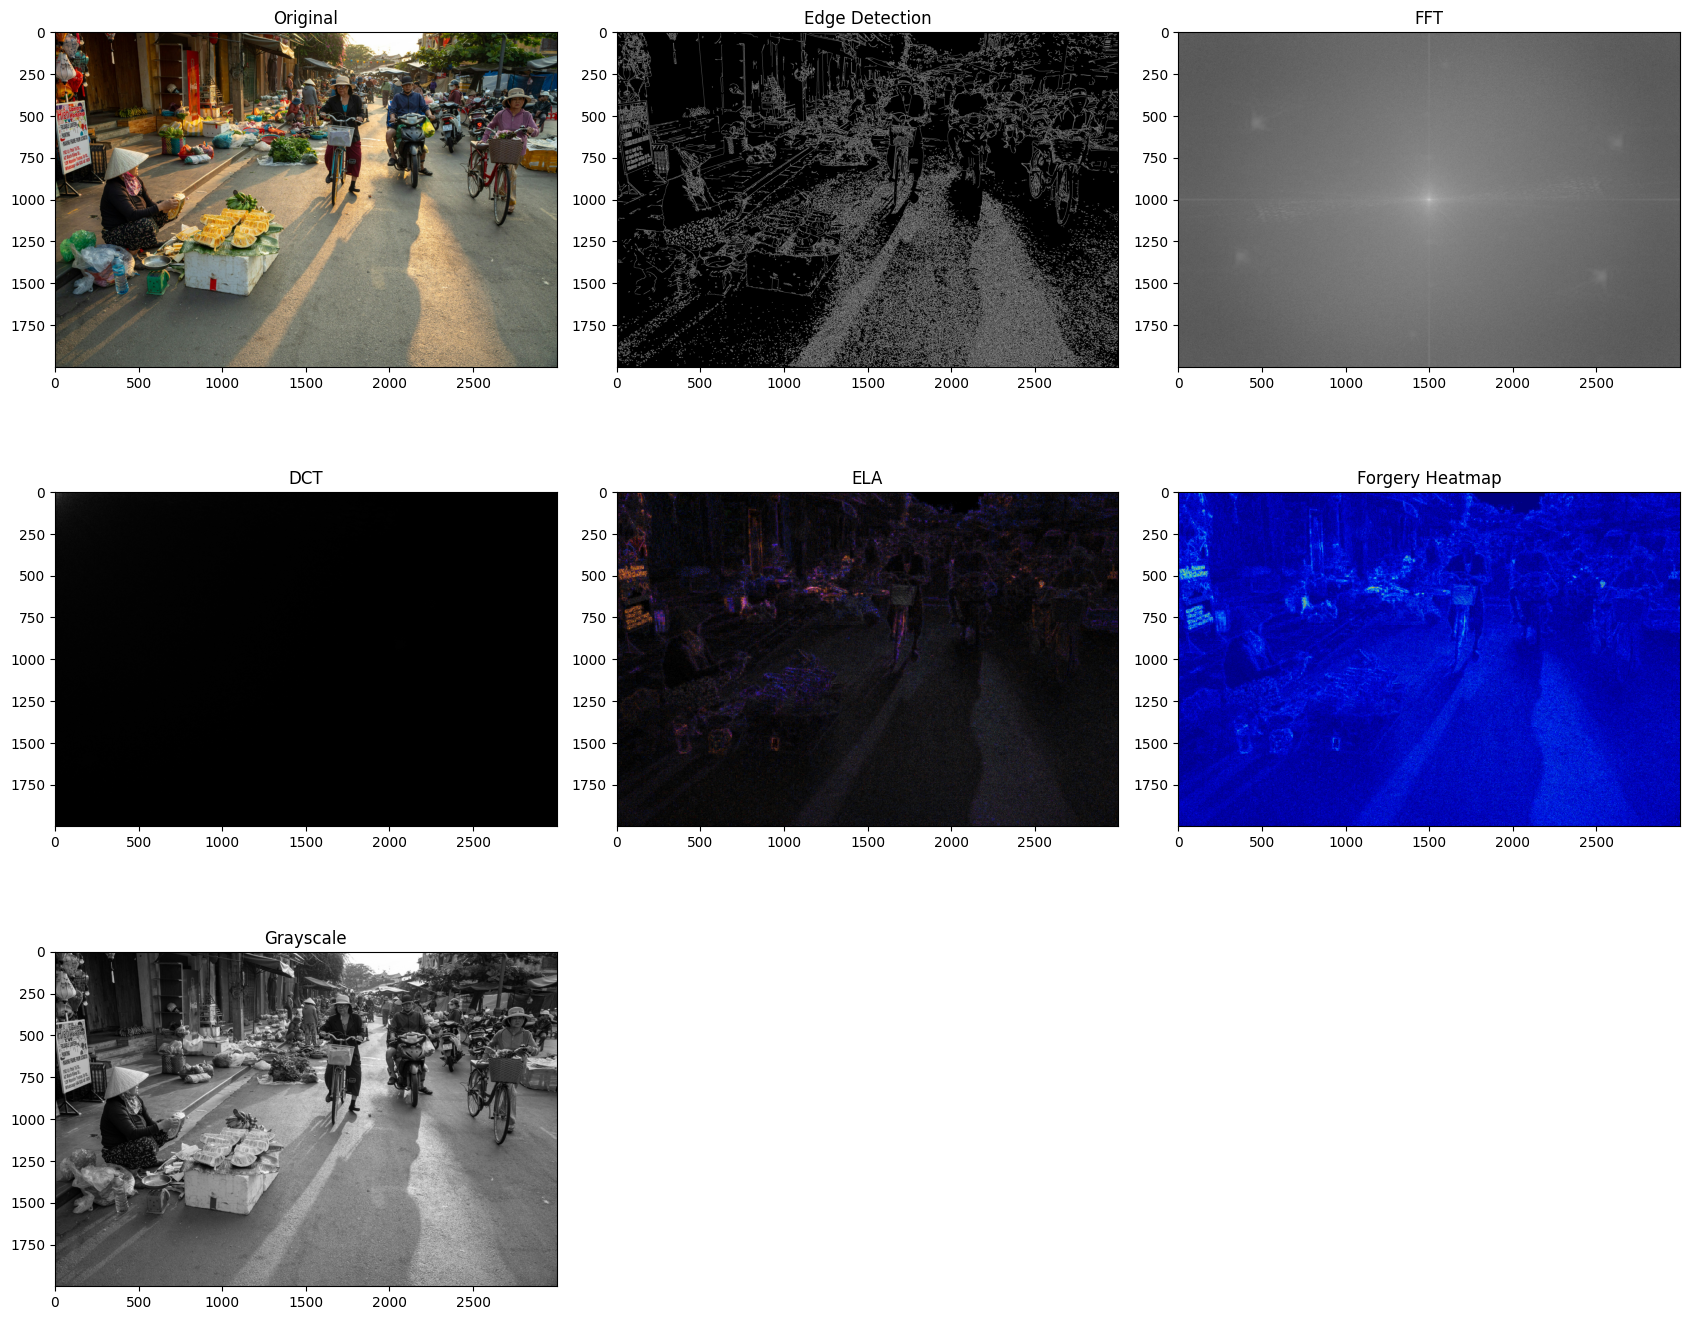

In [ ]:
plt.figure(figsize=(17,14))

plt.subplot(3,3,1)
plt.imshow(image)
plt.title("Original")

plt.subplot(3,3,2)
plt.imshow(edges,cmap='gray')
plt.title("Edge Detection")

plt.subplot(3,3,3)
plt.imshow(magnitude_spectrum,cmap='gray')
plt.title("FFT")

plt.subplot(3,3,4)
plt.imshow(np.log(abs(dct)+1),cmap='gray')
plt.title("DCT")

plt.subplot(3,3,5)
plt.imshow(ela)
plt.title("ELA")

plt.subplot(3,3,6)
plt.imshow(heatmap)
plt.title("Forgery Heatmap")

plt.subplot(3,3,7)
plt.imshow(gray,cmap='gray')
plt.title("Grayscale")

plt.tight_layout()
plt.show()

# **Step-11: Detect Tampered Regions**

(np.float64(-0.5), np.float64(2999.5), np.float64(1999.5), np.float64(-0.5))

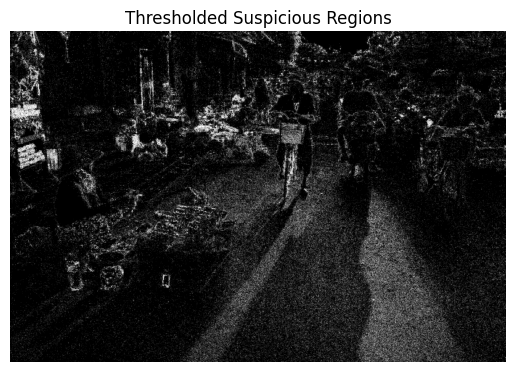

In [ ]:
ela_gray = cv2.cvtColor(ela, cv2.COLOR_RGB2GRAY)
ela_norm = cv2.normalize(ela_gray, None, 0, 255, cv2.NORM_MINMAX)

threshold_value = np.mean(ela_norm) + 20
_, thresh = cv2.threshold(ela_norm, threshold_value, 255, cv2.THRESH_BINARY)

plt.imshow(thresh, cmap='gray')
plt.title("Thresholded Suspicious Regions")
plt.axis("off")

# **Step-12: Find Contours (Detect Regions)**

(np.float64(-0.5), np.float64(2999.5), np.float64(1999.5), np.float64(-0.5))

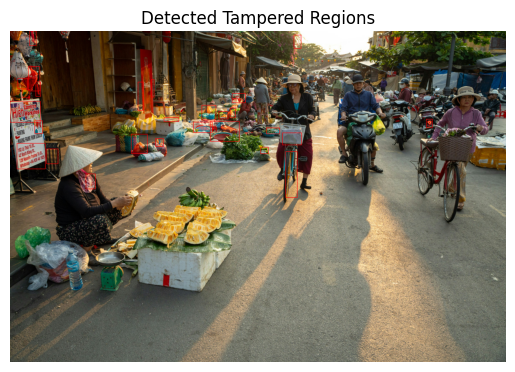

In [ ]:
contours, _ = cv2.findContours(thresh, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

output = image.copy()

for cnt in contours:
    if cv2.contourArea(cnt) > 500:   # filter small noise
        x, y, w, h = cv2.boundingRect(cnt)
        cv2.rectangle(output, (x, y), (x+w, y+h), (255,0,0), 2)

plt.imshow(output)
plt.title("Detected Tampered Regions")
plt.axis("off")

## ***RESULT***

In [ ]:
score = np.mean(ela_gray)

print("Forgery Score:", score)

if score > 25:
    print("Result: Suspicious (Possibly Manipulated)")
else:
    print("Result: Likely Authentic")

Forgery Score: 16.458629833333333
Result: Likely Authentic
